|<img src="https://www.udp.cl/cms/wp-content/uploads/2021/06/UDP_LogoRGB_2lineas_Color_SinFondo.png" width="500" height="100">| <p> Ciencias de Datos para la Economía</p>  <p> Ingeniería Comercial </p><p> Profesor: Luis Cuevas Parra </p><p>Unidad 4: Pre-procesamiento y Análisis Exploratorio de Indicadores</p><p> Limpieza, deflactación, estacionalidad y visualización de coyuntura con datos financieros </p>|
|---|---|

# Pre-procesamiento y análisis exploratorio de indicadores

Antes de estimar cualquier modelo, un analista pasa la mayor parte del tiempo **preparando los datos**:
completar o descartar datos faltantes, poner las series en la misma escala, quitar el efecto de la inflación
y entender qué mueve a cada serie. Un error en esta etapa contamina todo lo que viene después.

En este cuaderno trabajaremos con **datos financieros** (dólar, cobre, acciones, oro, petróleo) junto con los índices
de precios de Chile y Estados Unidos.

### Lo que aprenderemos

| # | Tema | Pregunta que responde |
|:-:|:---|:---|
| 1 | Datos | ¿De dónde salen y cómo los guardo? |
| 2 | Valores faltantes | ¿Por qué faltan datos y qué hago con ellos? |
| 3 | Cambios de base y empalmes | ¿Cómo comparo series en distintas unidades o con distinta base? |
| 4 | Nominal vs. real | ¿Cuánto de un cambio de precio es solo inflación? |
| 5 | Componentes y estacionalidad | ¿Todas las series tienen estacionalidad? |
| 6 | Visualización de coyuntura | ¿Cómo comparo contra el año anterior, quién explica un resultado y qué se mueve junto? |

### Mini-glosario

| Término | Significado en una línea |
|:---|:---|
| **Valor faltante** (`NaN`) | Una fecha sin dato: feriado, dato aún no publicado o error de captura. |
| **Índice / año base** | Número que expresa un nivel respecto a un período que vale 100. |
| **Empalme** | Unir una serie antigua y una nueva que tienen distinta base. |
| **Nominal** | Medido en dinero de cada momento (pesos o dólares "de ese día"). |
| **Real** | Medido en dinero de **poder de compra constante**: se le quitó la inflación. |
| **Deflactar** | Pasar de nominal a real, dividiendo por un índice de precios. |
| **Retorno** | Cambio porcentual del precio de un activo en un período. |
| **Contribución** | Parte de un resultado total que explica cada componente (peso × variación). |

## 0. Preparar el entorno

In [1]:
import warnings

import numpy as np
import pandas as pd
import requests
from pathlib import Path
from sqlalchemy import create_engine, text
import yfinance as yf
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10.5,
                     'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})

# Paleta de colores del curso
COLOR_UDP   = '#800020'   # serie principal
COLOR_TREND = '#1f77b4'   # tendencia / series reales
COLOR_OK    = '#2ca02c'   # lectura favorable
COLOR_ALERT = '#d62728'   # alertas
COLOR_ALT   = '#ff7f0e'   # comparación
COLOR_GRAY  = '#7f7f7f'   # series de fondo

MESES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

## 1. Datos

Trabajaremos con dos tablas: una **diaria** (precios de mercado) y una **mensual** (índices de precios y actividad).

| Nombre corto | Qué es | Fuente | Frecuencia |
|:---|:---|:---|:---|
| `dolar` | Dólar observado, pesos por dólar | Banco Central (base SQL del kit) | Diaria |
| `cobre` | Cobre en Nueva York (`HG=F`), US\$ por libra | Yahoo Finance | Diaria |
| `acciones_cl` | ETF de acciones chilenas en Nueva York (`ECH`), US\$ | Yahoo Finance | Diaria |
| `sp500` | Índice bursátil de EE.UU. (`^GSPC`), puntos | Yahoo Finance | Diaria |
| `oro` | Oro (`GC=F`), US\$ por onza | Yahoo Finance | Diaria |
| `brent` | Petróleo Brent (`BZ=F`), US\$ por barril | Yahoo Finance | Diaria |
| `ipc_canasta_2018`, `ipc_canasta_2023` | IPC de Chile de cada canasta, sin empalmar | Banco Central (`data/raw/ipc_canastas.db`) | Mensual |
| `ipc_cl` | IPC de Chile, serie empalmada oficial (2023 = 100) | Banco Central (`data/raw/ipc_canastas.db`) | Mensual |
| `ipc_eeuu` | IPC de Estados Unidos (`CPIAUCSL`) | FRED (base SQL del kit) | Mensual |
| `imacec` | Actividad económica de Chile (2018 = 100) | Banco Central (base SQL del kit) | Mensual |

**Yahoo Finance** no tiene una API oficial; usamos la librería **`yfinance`**, que descarga los precios en una línea
(si no la tienes: `pip install yfinance`). Al final del cuaderno, un anexo muestra cómo pedir los mismos datos "a mano" con `requests`.

Usamos **precios ajustados** (`auto_adjust=True`): incluyen los dividendos, así que reflejan lo que realmente ganó quien invirtió.

### 1.1 Precios de mercado desde Yahoo Finance

In [2]:
tickers = {'HG=F': 'cobre', 'ECH': 'acciones_cl', '^GSPC': 'sp500', 'GC=F': 'oro', 'BZ=F': 'brent'}

yahoo = yf.download(list(tickers), start='2016-10-01', auto_adjust=True, progress=False)
yahoo = yahoo['Close']                      # nos quedamos con el precio de cierre
yahoo = yahoo.rename(columns=tickers)       # nombres cortos
yahoo.tail()

Ticker,brent,acciones_cl,oro,cobre,sp500
Date,,,,,
2026-10-08,104.279999,37.680000,4157.000000,6.5190,7765.359863
2026-10-09,104.720001,37.730000,4216.299805,6.6425,7811.540039
2026-10-12,106.650002,37.779999,4190.600098,6.6985,7807.240234
2026-10-13,105.690002,37.389999,4177.299805,6.6780,7805.450195
2026-10-14,106.330002,NaN,4185.700195,6.7690,NaN


### 1.2 Series desde las bases SQL

Esta función lee **una** serie de una base SQLite del curso (lo visto en la Unidad 1). La usaremos varias veces.

In [9]:
# Rutas de las bases
BASE_KIT = Path("../../kit-inicio-coyuntura/data/coyuntura_2026-07-31.db")

BASE_CANASTAS = Path("../../Introducci-n_Python_An-lisis_Econ-mico/data/raw/ipc_canastas.db")

# Verificación de rutas
print("Existe BASE_KIT:", BASE_KIT.exists())

print("Existe BASE_CANASTA:", BASE_CANASTAS.exists())


Existe BASE_KIT: True
Existe BASE_CANASTA: True


In [10]:
# Un motor de conexión para cada base
engine_kit = create_engine(f"sqlite:///{BASE_KIT.resolve()}")
engine_canastas = create_engine(f"sqlite:///{BASE_CANASTAS.resolve()}")

def leer_serie(engine, codigo):
    consulta = text("""
        SELECT fecha, valor
        FROM observaciones
        WHERE id_serie = :codigo
    """)

    tabla = pd.read_sql(
        consulta,
        engine,
        params={"codigo": codigo},
        parse_dates=["fecha"],
        index_col="fecha"
    )

    return tabla["valor"]

# Leer desde la base del kit
dolar = leer_serie(engine_kit, "F073.TCO.PRE.Z.D")
dolar.tail()

fecha
2026-07-27    946.14
2026-07-28    941.93
2026-07-29    936.16
2026-07-30    935.57
2026-07-31    924.78
Name: valor, dtype: float64

### 1.3 Tabla diaria: juntar el dólar con los precios de Yahoo

`join(..., how='outer')` conserva **todas** las fechas de ambas tablas. Si un día hay dato en una y no en la otra,
queda un `NaN`: eso lo trabajamos en la sección 2.

In [11]:
diarios = yahoo.join(dolar.rename('dolar'), how='outer')
diarios.tail()

,brent,acciones_cl,oro,cobre,sp500,dolar
2026-10-08,104.279999,37.680000,4157.000000,6.5190,7765.359863,NaN
2026-10-09,104.720001,37.730000,4216.299805,6.6425,7811.540039,NaN
2026-10-12,106.650002,37.779999,4190.600098,6.6985,7807.240234,NaN
2026-10-13,105.690002,37.389999,4177.299805,6.6780,7805.450195,NaN
2026-10-14,106.330002,NaN,4185.700195,6.7690,NaN,NaN


### 1.4 Tabla mensual

In [12]:
mensuales = pd.DataFrame({
    'ipc_canasta_2018': leer_serie(engine_canastas, 'F074.IPC.IND.Z.2018.C.M'),
    'ipc_canasta_2023': leer_serie(engine_canastas, 'F074.IPC.IND.Z.2023.C.M'),
    'ipc_cl':           leer_serie(engine_canastas, 'F074.IPC.IND.Z.EP23.C.M'),
    'ipc_eeuu':         leer_serie(engine_canastas, 'CPIAUCSL'),
    'imacec':           leer_serie(engine_canastas, 'F032.IMC.IND.Z.Z.EP18.Z.Z.0.M'),
})
mensuales.tail()

,ipc_canasta_2018,ipc_canasta_2023,ipc_cl,ipc_eeuu,imacec
fecha,,,,,
2026-04-01,NaN,112.18,112.18,NaN,NaN
2026-05-01,NaN,112.37,112.37,NaN,NaN
2026-06-01,NaN,112.35,112.35,NaN,NaN
2026-07-01,NaN,112.45,112.45,NaN,NaN
2026-08-01,NaN,113.15,113.15,NaN,NaN


### 1.5 Guardar en Parquet

Como en el cuaderno U2-01: guardamos las tablas para poder leerlas después sin volver a descargar.

In [13]:
diarios.to_parquet('../data/diarios.parquet')
mensuales.to_parquet('../data/mensuales.parquet')

## 2. Valores faltantes

Al juntar series de distintas fuentes en una sola tabla, aparecen celdas vacías (`NaN`). Las causas típicas son:

| Causa | Ejemplo en nuestros datos |
|:---|:---|
| **Calendarios distintos** | El 18 y 19 de septiembre (Fiestas Patrias) no hay dólar observado, pero Nueva York abre. El 4 de julio pasa lo contrario. |
| **Series que empiezan en fechas distintas** | El dólar observado parte en 2010; las series de Yahoo, en 2016. |
| **Datos aún no publicados** | La base del kit llega hasta el 31-jul-2026; Yahoo, hasta octubre. |
| **Errores de captura** | Un precio que no se registró ese día (o uno absurdo, que conviene convertir a `NaN`). |

**Primer paso siempre: diagnosticar** cuántos faltan, dónde y por qué. Recién después se decide qué hacer.

El método apply() permite ejecutar una función sobre cada elemento de una serie o sobre las filas o columnas de un DataFrame.

Una función lambda es una función breve y anónima que se escribe en una sola línea. Ambas suelen utilizarse conjuntamente para crear o transformar variables:

```python
df['categoria'] = df['valor'].apply(
    lambda x: 'alto' if x >= 100 else 'bajo'
)
```

En este ejemplo, apply() recorre los valores de la columna valor, mientras que lambda clasifica cada valor como "alto" o "bajo".

La expresión general es 
```python
serie.apply(lambda x: transformación_de_x)
```

Para operaciones simples, es preferible utilizar métodos vectorizados de pandas, porque suelen ser más rápidos. apply() es especialmente útil cuando la transformación requiere una lógica personalizada.

In [14]:
diagnostico = pd.DataFrame({
    'primer dato':  diarios.apply(lambda s: s.first_valid_index()),
    'último dato':  diarios.apply(lambda s: s.last_valid_index()),
    'faltantes':    diarios.isna().sum(),
    '% faltante':   (diarios.isna().mean() * 100).round(1),
})
diagnostico

,primer dato,último dato,faltantes,% faltante
brent,2016-10-03,2026-10-14,1755,41.0
acciones_cl,2016-10-03,2026-10-13,1757,41.1
oro,2016-10-03,2026-10-14,1756,41.0
cobre,2016-10-03,2026-10-14,1756,41.0
sp500,2016-10-03,2026-10-13,1757,41.1
dolar,2010-01-04,2026-07-31,149,3.5


Recortemos al período en que **todas** las series existen, y miremos una semana con feriados en Chile:

In [15]:
inicio = diagnostico['primer dato'].max()     
fin    = diagnostico['último dato'].min() 
comun = diarios.loc[inicio:fin]
print(f'Período común: {inicio:%Y-%m-%d} a {fin:%Y-%m-%d}')

comun.loc['2025-09-15':'2025-09-23']

Período común: 2016-10-03 a 2026-07-31


,brent,acciones_cl,oro,cobre,sp500,dolar
2025-09-15,67.440002,33.156387,3719.000000,4.6555,6615.279785,954.58
2025-09-16,68.470001,33.117142,3725.100098,4.6330,6606.759766,951.14
2025-09-17,67.949997,32.764008,3717.800049,4.5710,6600.350098,948.57
2025-09-18,67.440002,32.960194,3678.300049,4.5410,6631.959961,NaN
2025-09-19,66.680000,32.950382,3705.800049,4.5690,6664.359863,NaN
2025-09-22,66.570000,32.862099,3775.100098,4.5730,6693.750000,951.03
2025-09-23,67.629997,33.038670,3815.699951,4.5845,6656.919922,954.72


### ¿Qué hacer con los faltantes?

| Estrategia | Código | Cuándo sirve | Riesgo |
|:---|:---|:---|:---|
| **Eliminar filas** | `dropna()` | Comparar series día a día (retornos, correlaciones) usando solo días en que todas tienen dato | Se pierden observaciones |
| **Arrastrar el último valor** | `ffill()` | Precios: el último precio conocido sigue vigente mientras el mercado está cerrado | Si el hueco es largo, se arrastra un dato viejo (usar `limit=`) |
| **Interpolar** | `interpolate()` | Dibujar o describir el pasado | **Usa el dato siguiente**: nunca para pronosticar (look-ahead bias) |
| **Agregar a menor frecuencia** | `resample('MS').mean()` | Pasar de diario a mensual: el promedio ignora los `NaN` | Se pierde detalle diario |

Comparemos las tres primeras sobre el dólar en Fiestas Patrias 2025:

In [16]:
semana = slice('2025-09-15', '2025-09-23')

comparacion = pd.DataFrame({
    'original': comun['dolar'],

    # Reemplaza cada dato faltante por el último valor válido observado.
    'forward_fill': comun['dolar'].ffill(),

    # Reemplaza cada dato faltante por el siguiente valor válido.
    'backward_fill': comun['dolar'].bfill(),

    # Interpola linealmente según la posición de las observaciones.
    'interpolate_linear': comun['dolar'].interpolate(method='linear'),

    # Interpola considerando la distancia entre los valores del índice.
    'interpolate_index': comun['dolar'].interpolate(method='index'),

    # Utiliza el valor conocido más cercano al dato faltante.
    'interpolate_nearest': comun['dolar'].interpolate(method='nearest'),

    # Ajusta un polinomio cuadrático para estimar los datos faltantes.
    'interpolate_polynomial': comun['dolar'].interpolate(
        method='polynomial',
        order=2
    ),

    # Ajusta una curva spline cúbica suave para estimar los datos faltantes.
    'interpolate_spline': comun['dolar'].interpolate(
        method='spline',
        order=3
    )
}).loc[semana]

comparacion

,original,forward_fill,backward_fill,interpolate_linear,interpolate_index,interpolate_nearest,interpolate_polynomial,interpolate_spline
2025-09-15,954.58,954.58,954.58,954.58,954.580,954.58,954.580000,954.58000
2025-09-16,951.14,951.14,951.14,951.14,951.140,951.14,951.140000,951.14000
2025-09-17,948.57,948.57,948.57,948.57,948.570,948.57,948.570000,948.57000
2025-09-18,NaN,948.57,951.03,949.39,949.062,948.57,946.913954,945.55736
2025-09-19,NaN,948.57,951.03,950.21,949.554,948.57,946.066881,945.44837
2025-09-22,951.03,951.03,951.03,951.03,951.030,951.03,951.030000,951.03000
2025-09-23,954.72,954.72,954.72,954.72,954.720,954.72,954.720000,954.72000


In [18]:
print(f'Filas del período común:  {len(comun)}')
print(f'Filas tras dropna():      {len(comun.dropna())}   (solo días con todas las series)')
print(f'Faltantes tras ffill():   {comun.ffill().isna().sum().sum()}')

Filas del período común:  2539
Filas tras dropna():      2371   (solo días con todas las series)
Faltantes tras ffill():   0


> **Decisión para este cuaderno:** para comparar series **diarias** usaremos solo los días con todas las series (`dropna`);
> para pasar a **mensual** usaremos `resample`, que ignora los faltantes. Lo importante es **decidir a propósito y dejarlo escrito**.

### De diario a mensual: ¿promedio o cierre?

`resample('MS')` agrupa por mes (`'MS'` = *month start*: cada mes queda fechado el día 1). Hay que elegir cómo resumir:

* **Promedio del mes** (`.mean()`): representa el nivel típico del mes. Es lo que se usa para indicadores macro (ej. "dólar promedio de julio").
* **Último dato del mes** (`.last()`): el precio al cierre. Es lo que se usa para calcular **retornos** de inversiones.

In [19]:
# Solo hasta el último día común ('fin'), para no mezclar meses incompletos
prom_mensual   = diarios.loc[:fin].resample('MS').mean()
cierre_mensual = diarios.loc[:fin].resample('MS').last()

pd.DataFrame({'dólar promedio del mes': prom_mensual['dolar'],
              'dólar al cierre del mes': cierre_mensual['dolar']}).tail(6).round(1)

,dólar promedio del mes,dólar al cierre del mes
2026-02-01,862.0,861.2
2026-03-01,909.9,931.6
2026-04-01,897.9,901.8
2026-05-01,897.6,892.9
2026-06-01,903.4,922.3
2026-07-01,931.0,924.8


In [20]:
# Tabla mensual de trabajo: promedios de mercado + índices de precios y actividad
mensual = prom_mensual.join(mensuales, how='outer')
mensual.tail(4).round(2)

,brent,acciones_cl,oro,cobre,sp500,dolar,ipc_canasta_2018,ipc_canasta_2023,ipc_cl,ipc_eeuu,imacec
2026-05-01,104.09,40.26,4598.23,6.26,7412.55,897.64,NaN,112.37,112.37,NaN,NaN
2026-06-01,84.62,39.80,4257.85,6.32,7450.03,903.38,NaN,112.35,112.35,NaN,NaN
2026-07-01,84.51,39.36,4078.74,6.28,7481.34,930.97,NaN,112.45,112.45,NaN,NaN
2026-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,113.15,113.15,NaN,NaN


## Anexo: los mismos datos, pedidos "a mano" con `requests`

`yfinance` consulta una dirección web de Yahoo. Podemos pedirla directamente con `requests`, igual que hicimos con la
API del Banco Mundial en U2-01. Sirve para entender qué hace la librería por dentro y como plan B si deja de funcionar.

La diferencia: las fechas vienen en **segundos desde 1970** y hay que convertirlas, y el precio no viene ajustado por dividendos.

In [21]:
url = 'https://query1.finance.yahoo.com/v8/finance/chart/HG=F'
respuesta = requests.get(url, params={'range': '1mo', 'interval': '1d'},
                         headers={'User-Agent': 'Mozilla/5.0'}, timeout=30)
datos = respuesta.json()['chart']['result'][0]

fechas = pd.to_datetime(datos['timestamp'], unit='s')            # segundos -> fechas
cierre = datos['indicators']['quote'][0]['close']                # precios de cierre

pd.Series(cierre, index=fechas, name='cobre').tail()

2026-10-08 04:00:00    6.5190
2026-10-09 04:00:00    6.6425
2026-10-12 04:00:00    6.6985
2026-10-13 04:00:00    6.6780
2026-10-14 04:00:00    6.7625
Name: cobre, dtype: float64

In [22]:
import requests
import pandas as pd


def descargar_yahoo(ticker, inicio, fin=None, frecuencia="1d"):
    # Si no se indica fecha final, usa la fecha actual.
    fin = pd.Timestamp.today() if fin is None else pd.Timestamp(fin)

    url = f"https://query1.finance.yahoo.com/v8/finance/chart/{ticker}"

    parametros = {
        "period1": int(pd.Timestamp(inicio).timestamp()),
        "period2": int((fin + pd.Timedelta(days=1)).timestamp()),
        "interval": frecuencia
    }

    respuesta = requests.get(
        url,
        params=parametros,
        headers={"User-Agent": "Mozilla/5.0"},
        timeout=30
    )

    datos = respuesta.json()["chart"]["result"][0]

    fechas = pd.to_datetime(datos["timestamp"], unit="s")
    cierres = datos["indicators"]["quote"][0]["close"]

    return pd.Series(cierres, index=fechas, name=ticker).dropna()

In [23]:
# Cobre diario desde 2020 hasta hoy
cobre = descargar_yahoo("HG=F", "2020-01-01")
cobre

2020-01-02 05:00:00    2.8330
2020-01-03 05:00:00    2.7985
2020-01-06 05:00:00    2.8005
2020-01-07 05:00:00    2.8040
2020-01-08 05:00:00    2.8190
                        ...  
2026-10-08 04:00:00    6.5190
2026-10-09 04:00:00    6.6425
2026-10-12 04:00:00    6.6985
2026-10-13 04:00:00    6.6780
2026-10-14 04:00:00    6.7625
Name: HG=F, Length: 1708, dtype: float64

In [24]:
# S&P 500 semanal entre dos fechas
sp500 = descargar_yahoo(
    "^GSPC",
    inicio="2020-01-01",
    fin="2025-12-31",
    frecuencia="1wk"
)

display(sp500)

2020-01-01 05:00:00    3237.179932
2020-01-08 05:00:00    3283.149902
2020-01-15 05:00:00    3320.790039
2020-01-22 05:00:00    3276.239990
2020-01-29 05:00:00    3297.590088
                          ...     
2025-12-03 05:00:00    6840.509766
2025-12-10 05:00:00    6800.259766
2025-12-17 05:00:00    6909.790039
2025-12-24 05:00:00    6896.240234
2025-12-31 05:00:00    6845.500000
Name: ^GSPC, Length: 314, dtype: float64

## 3. Cambios de base y empalmes

### 3.1 Cambio de base: ¿qué precio aumentó más?

El cobre se expresa en dólares por libra, el S&P 500 en puntos y el dólar en pesos chilenos por dólar. Como tienen
unidades y escalas diferentes, sus niveles no pueden compararse directamente en un mismo gráfico.

Veamos que ocurre si comparamos de manera directa:

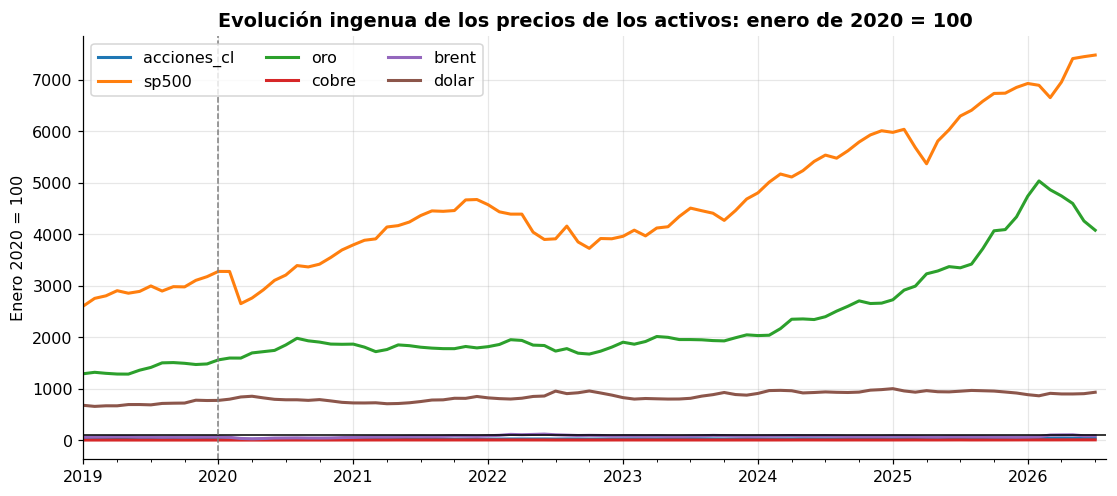

sp500          7481.0
oro            4079.0
dolar           931.0
brent            85.0
acciones_cl      39.0
cobre             6.0
Name: 2026-07-01 00:00:00, dtype: float64

In [25]:
BASE = '2020-01'
activos = ['acciones_cl', 'sp500', 'oro', 'cobre', 'brent', 'dolar']

indices_ingenuo = mensual[activos].loc['2019':]
ax = indices_ingenuo.plot(figsize=(12, 5), lw=2)
ax.legend(ncol=3, loc='upper left')
ax.axhline(100, color='black', lw=1)
ax.axvline(pd.Timestamp(BASE), color='gray', ls='--', lw=1)
ax.set_ylabel('Enero 2020 = 100')
ax.set_xlabel('')
ax.set_title(
    'Evolución ingenua de los precios de los activos: enero de 2020 = 100',
    fontweight='bold'
)
plt.show()

indices_ingenuo.dropna().iloc[-1].sort_values(ascending=False).round(0)

El **cambio de base** transforma cada serie en un índice y hace que todas tengan el valor 100 en un mismo período.
Esto permite comparar cuánto aumentó o disminuyó cada serie respecto de ese período, sin importar su unidad original:

$$
\text{Índice}_t =
\frac{\text{Serie}_t}
{\text{promedio de la serie en el período base}}
\times 100
$$

La interpretación es directa:

- Un índice de **100** indica que el valor es igual al promedio del período base.
- Un índice de **150** representa un aumento de 50% respecto del período base.
- Un índice de **80** representa una disminución de 20%.

El cambio de base modifica la escala, pero no altera las variaciones porcentuales de la serie.

In [26]:
def cambio_base(serie, periodo_base):
    # Reescala la serie para que el promedio del período base valga 100
    return serie / serie.loc[periodo_base].mean() * 100

In [27]:
indices = pd.DataFrame({a: cambio_base(mensual[a], BASE) for a in activos}).loc['2019':]

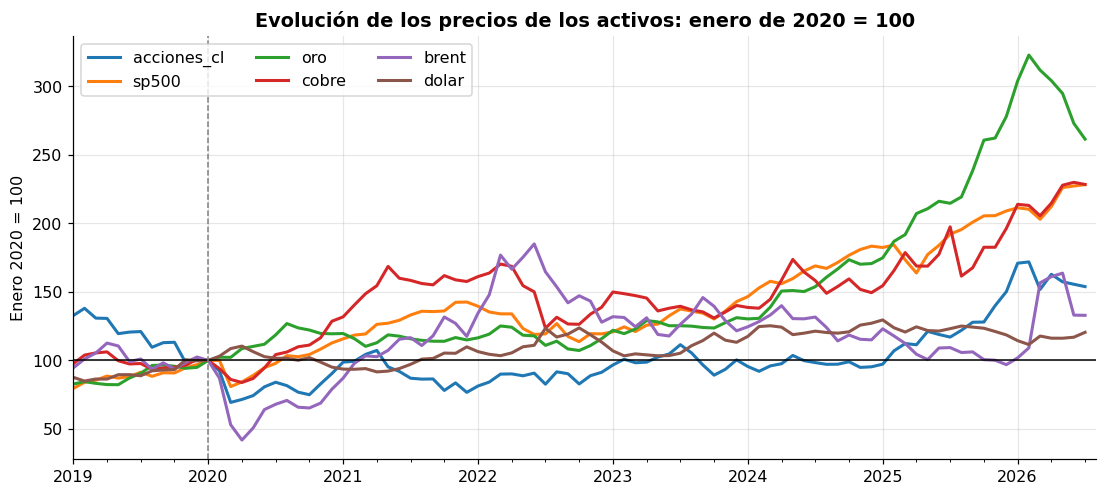

oro            261.0
cobre          228.0
sp500          228.0
acciones_cl    154.0
brent          133.0
dolar          120.0
Name: 2026-07-01 00:00:00, dtype: float64

In [28]:
ax = indices.plot(figsize=(12, 5), lw=2)
ax.legend(ncol=3, loc='upper left')
ax.axhline(100, color='black', lw=1)
ax.axvline(pd.Timestamp(BASE), color='gray', ls='--', lw=1)
ax.set_ylabel('Enero 2020 = 100')
ax.set_xlabel('')
ax.set_title(
    'Evolución de los precios de los activos: enero de 2020 = 100',
    fontweight='bold'
)
plt.show()

indices.dropna().iloc[-1].sort_values(ascending=False).round(0)

### 3.2 Empalme del IPC de Chile

En enero de 2024 el INE cambió la canasta del IPC: la serie antigua (promedio 2018 = 100) terminó cerca de 134
y la nueva (promedio 2023 = 100) partió cerca de 101. Pegarlas crearía una "deflación" falsa de 24%.

El **empalme con factor de enlace** usa un mes en que existen ambas series (diciembre de 2023):
$$k = \frac{\text{Serie nueva}_{\text{dic-2023}}}{\text{Serie antigua}_{\text{dic-2023}}}$$
y multiplica toda la historia antigua por $k$. (El cuaderno U2-04 desarrolla este tema en detalle.)

In [29]:
antigua = mensual['ipc_canasta_2018'].dropna()
nueva   = mensual['ipc_canasta_2023'].dropna()
MES_EMPALME = '2023-12-01'

k = nueva.loc[MES_EMPALME] / antigua.loc[MES_EMPALME]
ipc_empalmado = pd.concat([antigua.loc[:MES_EMPALME].iloc[:-1] * k, nueva.loc[MES_EMPALME:]])

diferencia = (ipc_empalmado - mensual['ipc_cl']).loc['2019':].abs().max()
print(f'k = {k:.4f}')
print(f'Diferencia máxima con la serie empalmada oficial (desde 2019): {diferencia:.2f} puntos (redondeo)')

k = 0.7535
Diferencia máxima con la serie empalmada oficial (desde 2019): 0.01 puntos (redondeo)


> Nuestro empalme reproduce el oficial. Como la serie oficial `ipc_cl` además se extiende hasta 2010, **es la que usaremos para deflactar** en la siguiente sección.

## 4. Datos nominales vs. reales: deflactar

Un precio **nominal** está expresado en el dinero de cada momento. Sin embargo, el dinero pierde poder adquisitivo
con la inflación: 100 dólares de 2017 no compran lo mismo que 100 dólares de 2026.

Un precio **real** expresa los valores de diferentes fechas utilizando el poder adquisitivo de un mismo período.
Por ejemplo, podemos convertir toda la serie a "dólares de junio de 2026".

**Deflactar** consiste en transformar una serie nominal en una serie real mediante un índice de precios:

$$
\text{Real}_t =
\text{Nominal}_t
\times
\frac{\text{IPC}_{\text{período base}}}
{\text{IPC}_t}
$$

La elección del deflactor depende del objetivo del análisis. En este ejemplo utilizamos el IPC de Estados Unidos
para expresar el precio del cobre en dólares con poder adquisitivo constante estadounidense.

### 4.1 El precio real del cobre

In [30]:
import pandas as pd

# CPIAUCNS: IPC general de Estados Unidos sin ajuste estacional.
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCNS"

ipc_eeuu = (
    pd.read_csv(
        url,
        parse_dates=["observation_date"],
        index_col="observation_date"
    )["CPIAUCNS"]
    .rename("ipc_eeuu")
    .dropna()
)

# Unir datos del cobre e ipc 
datos_cobre = pd.concat([mensual["cobre"].rename("cobre_nominal"),ipc_eeuu],
    axis=1,
    join="inner"
).dropna()


In [31]:
# Último mes con información disponible para ambas series.
mes_base = datos_cobre.index[-1]

print(f"Mes base: {mes_base:%m-%Y}")

cobre_nominal = datos_cobre["cobre_nominal"]

# Convertimos los precios a dólares con poder adquisitivo del mes base.
cobre_real = (cobre_nominal * datos_cobre.loc[mes_base, "ipc_eeuu"]/ datos_cobre["ipc_eeuu"])

print("Precio nominal del cobre:")
display(cobre_nominal.tail())

print("\nPrecio real del cobre:")
display(cobre_real.tail())

Mes base: 07-2026
Precio nominal del cobre:


2026-03-01    5.651659
2026-04-01    5.903571
2026-05-01    6.264200
2026-06-01    6.322357
2026-07-01    6.280182
Name: cobre_nominal, dtype: float64


Precio real del cobre:


2026-03-01    5.715071
2026-04-01    5.919491
2026-05-01    6.241676
2026-06-01    6.321713
2026-07-01    6.280182
dtype: float64

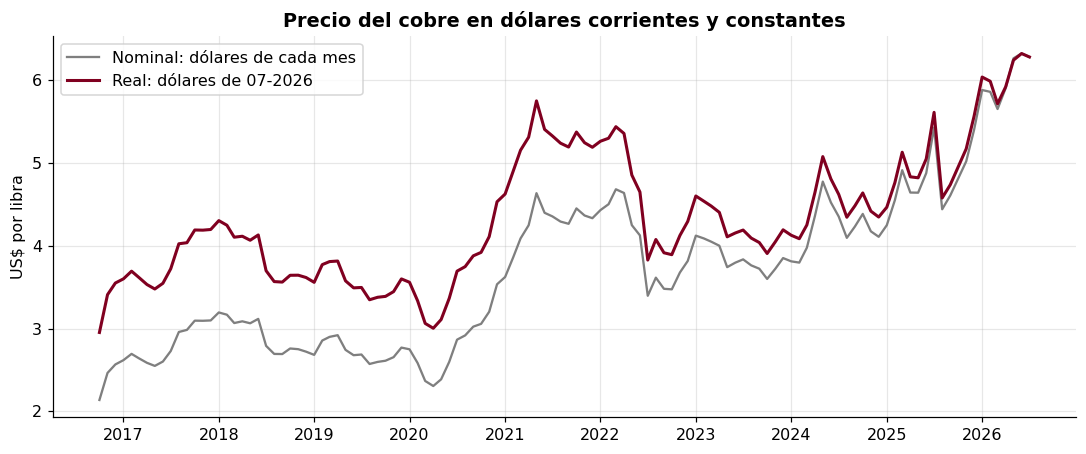

In [32]:
fig, ax = plt.subplots(figsize=(12, 4.5))

ax.plot(cobre_nominal,color=COLOR_GRAY,lw=1.5,label="Nominal: dólares de cada mes")

ax.plot(cobre_real,color=COLOR_UDP,lw=2,label=f"Real: dólares de {mes_base:%m-%Y}")

ax.set_ylabel("US$ por libra")
ax.set_xlabel("")
ax.set_title("Precio del cobre en dólares corrientes y constantes",fontweight="bold")
ax.legend()
plt.show()

In [33]:
inicio_cobre = datos_cobre.index[0]

inflacion_eeuu = (datos_cobre.loc[mes_base, "ipc_eeuu"]/ datos_cobre.loc[inicio_cobre, "ipc_eeuu"]- 1) * 100

cambio_nominal = (cobre_nominal.loc[mes_base]/ cobre_nominal.loc[inicio_cobre]- 1) * 100

cambio_real = (cobre_real.loc[mes_base]/ cobre_real.loc[inicio_cobre]- 1) * 100

print(f"Inflación de EE.UU. entre {inicio_cobre:%m-%Y} y {mes_base:%m-%Y}: {inflacion_eeuu:.1f}%")

print(f"Cobre nominal: {cambio_nominal:+.1f}% | Cobre real: {cambio_real:+.1f}%")

Inflación de EE.UU. entre 10-2016 y 07-2026: 38.1%
Cobre nominal: +193.8% | Cobre real: +112.7%


>La variación nominal muestra cuánto cambió el precio observado del cobre en dólares corrientes. La variación real descuenta la inflación estadounidense y expresa todos los precios en dólares con el poder adquisitivo del mes base.
>
> Si hubo inflación positiva durante el período, el aumento real será menor que el nominal. Los precios antiguos aparecen por encima de sus valores nominales porque se convierten a dólares actuales: un dólar antiguo tenía mayor poder adquisitivo que un dólar del período base.
>
> Este resultado depende del deflactor seleccionado. En este ejemplo, “real” significa ajustado por el IPC de Estados Unidos.

### 4.2 El tipo de cambio real

El dólar en Chile pasó de ~500 pesos en 2010 a más de 900 en la actualidad. ¿Significa que Chile se volvió casi el doble de "barato" para un comprador extranjero?

No necesariamente: en ese mismo período, la inflación acumulada en Chile fue mayor que en EE.UU. El **tipo de cambio real (TCR)** corrige por esta diferencia de precios relativos:

$$\text{TCR}_t = \text{Dólar}_t \times \frac{\text{IPC EE.UU.}_t}{\text{IPC Chile}_t}$$

> **Intuición:** El numerador ($\text{Dólar}_t \times \text{IPC EE.UU.}_t$) representa el costo de una canasta estadounidense expresado en pesos chilenos. Al dividirlo por el IPC de Chile, comparamos el costo de ambas canastas en la misma moneda:
> 
> - Si el TCR **sube**, la canasta externa se encarece frente a la local: los bienes chilenos se abaratan relativamente (depreciación real del peso / mayor competitividad).
> - Si el TCR **baja**, los bienes chilenos se encarecen frente a los externos (apreciación real / pérdida de competitividad).

Como los IPC provienen de bases distintas, el valor absoluto del TCR no tiene una unidad intuitiva. Por eso se analiza como **índice** (aquí normalizado a promedio 2018 = 100). 

*(Nota: Este cálculo es el TCR **bilateral** con EE.UU.; el Banco Central de Chile publica además un TCR **multilateral**, que promedia y pondera a nuestros principales socios comerciales).*


In [40]:
datos_tcr = pd.concat([mensual[['dolar',  'ipc_cl']], ipc_eeuu], axis = 1).dropna()
tcr = datos_tcr['dolar'] * datos_tcr['ipc_eeuu'] / datos_tcr['ipc_cl']

comparacion = pd.DataFrame({
    'Dólar nominal': cambio_base(datos_tcr['dolar'], '2018'),
    'Tipo de cambio real': cambio_base(tcr, '2018'),
})


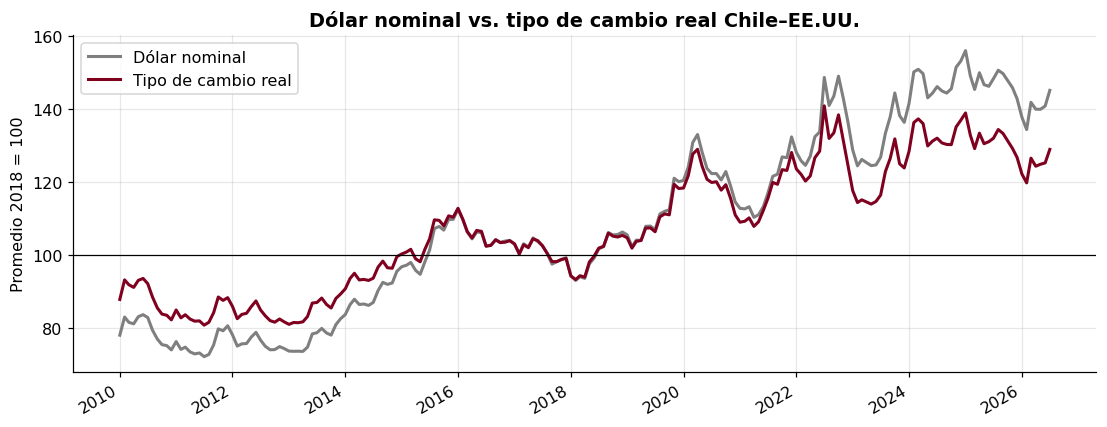

Cambio entre 01-2010 y 07-2026:
Dólar nominal          85.9
Tipo de cambio real    46.8


In [41]:
ax = comparacion.plot(figsize=(12, 4.5), color=[COLOR_GRAY, COLOR_UDP], lw=2)
ax.axhline(100, color='black', lw=0.8)
ax.set_ylabel('Promedio 2018 = 100')
ax.set_xlabel('')
ax.set_title('Dólar nominal vs. tipo de cambio real Chile–EE.UU.', fontweight='bold')
plt.show()

primero, ultimo = comparacion.index[0], comparacion.index[-1]
cambio = (comparacion.loc[ultimo] / comparacion.loc[primero] - 1) * 100
print(f'Cambio entre {primero:%m-%Y} y {ultimo:%m-%Y}:')
print(cambio.round(1).to_string())

> El dólar nominal subió con mucha mayor fuerza que el tipo de cambio real (en el gráfico, la brecha entre la curva gris y la bordó se ensancha con los años). 
> 
> La diferencia se explica por la mayor inflación acumulada en Chile: una parte importante del alza del dólar no abarató al país, sino que simplemente compensó que los precios internos en pesos subieron más rápido que en EE.UU.
> 
> **Mirar únicamente el tipo de cambio nominal distorsiona la realidad: para evaluar si un país se encareció o se volvió más competitivo frente al exterior, siempre se debe analizar el tipo de cambio real.**
